# Exploratory Data Analysis (EDA)
## Maternal Preterm Birth Prediction

**Dataset:** CDC/NCHS 2025 Natality Public Use File

**Objective:** Understand the dataset, examine its features, identify missing and invalid values, and analyze the target distribution before preprocessing and model development.

In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("natality_sample.csv")

# Display the first 5 rows
df.head()

,maternal_age_group,maternal_education,prior_live_births_now_living,prior_live_births_now_dead,prepregnancy_bmi,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,plurality,preterm_birth
0,20_24,high_school_or_GED,1.0,0.0,26.6,no,no,no,singleton,0
1,25_29,high_school_or_GED,2.0,0.0,28.3,no,no,no,singleton,0
2,35_39,associate_degree,1.0,0.0,35.7,no,no,no,singleton,0
3,35_39,bachelor_degree,2.0,0.0,22.5,no,no,yes,singleton,0
4,35_39,doctorate_or_professional_degree,0.0,0.0,29.8,no,no,no,singleton,0


In [3]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
print("\nDataset information:")
df.info()

Dataset shape: (10000, 10)

Columns:
['maternal_age_group', 'maternal_education', 'prior_live_births_now_living', 'prior_live_births_now_dead', 'prepregnancy_bmi', 'prepregnancy_diabetes', 'prepregnancy_hypertension', 'previous_preterm_birth', 'plurality', 'preterm_birth']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   maternal_age_group            10000 non-null  str    
 1   maternal_education            9859 non-null   str    
 2   prior_live_births_now_living  9923 non-null   float64
 3   prior_live_births_now_dead    9616 non-null   float64
 4   prepregnancy_bmi              9660 non-null   float64
 5   prepregnancy_diabetes         9930 non-null   str    
 6   prepregnancy_hypertension     9930 non-null   str    
 7   previous_preterm_birth        9930 non-null   str    
 8   plurality   


### 1. Maternal Age Group (`maternal_age_group`)

**Description:** Mother's age group at delivery.

**Variable type:** Categorical (Ordinal).

**Number of categories:** 13.

**Missing values:** 0.

**Main observations:**
- The most frequent category is `25_29` (28.49%).
- The second most frequent category is `30_34` (27.89%).
- Together, these two categories represent 56.38% of the dataset.
- Extreme age groups are very rare in this sample.

**Preprocessing consideration:**
Ordinal encoding may be considered because the categories follow a natural age order. The mapping must preserve the correct order. The encoding strategy will be finalized during preprocessing.


In [4]:
# Examine the maternal_age_group variable

column = "maternal_age_group"

print("Data type:")
print(df[column].dtype)

print("\nUnique categories:")
print(df[column].unique())

print("\nCategory frequencies:")
print(df[column].value_counts(dropna=False))

print("\nNumber of distinct categories:")
print(df[column].nunique(dropna=False))

print("\nNumber of missing values:")
print(df[column].isna().sum())

Data type:
str

Unique categories:
<StringArray>
[   '20_24',    '25_29',    '35_39',    '30_34',    '40_44',       '18',
       '19',    '45_49',       '17',       '16',       '15', 'under_15',
    '50_54']
Length: 13, dtype: str

Category frequencies:
maternal_age_group
25_29       2849
30_34       2789
20_24       1967
35_39       1649
40_44        363
19           190
18            93
17            55
16            20
45_49         12
15             7
under_15       4
50_54          2
Name: count, dtype: int64

Number of distinct categories:
13

Number of missing values:
0



### 2. Maternal Education (`maternal_education`)

**Description:** Mother's educational attainment.

**Variable type:** Categorical (Ordinal).

**Number of categories:** 8.

**Missing values:** 141 (1.41%).

**Most frequent category:** `high_school_or_GED` (3,360 observations).

**Main observations:**
- High school or GED is the most frequent education category.
- Some college without a degree is the second most frequent category.
- The education levels follow a natural order, from grade 8 or less to doctorate or professional degree.
- 141 observations have missing education information.

**Preprocessing consideration:**
Ordinal encoding may be appropriate because education categories follow a natural order. Missing-value treatment will be determined during preprocessing.


In [5]:
# Examine the maternal_education variable

column = "maternal_education"

print("Data type:")
print(df[column].dtype)

print("\nUnique categories:")
print(df[column].unique())

print("\nCategory frequencies:")
print(df[column].value_counts(dropna=False))

print("\nNumber of distinct categories:")
print(df[column].nunique(dropna=False))

print("\nNumber of missing values:")
print(df[column].isna().sum())

Data type:
str

Unique categories:
<StringArray>
[              'high_school_or_GED',                 'associate_degree',
                  'bachelor_degree', 'doctorate_or_professional_degree',
                                nan,                   'masters_degree',
           'some_college_no_degree',         'grade_9_to_12_no_diploma',
                  'grade_8_or_less']
Length: 9, dtype: str

Category frequencies:
maternal_education
high_school_or_GED                  3360
some_college_no_degree              2107
bachelor_degree                     1869
associate_degree                     739
masters_degree                       722
grade_9_to_12_no_diploma             715
doctorate_or_professional_degree     261
NaN                                  141
grade_8_or_less                       86
Name: count, dtype: int64

Number of distinct categories:
9

Number of missing values:
141



### 3. Previous Live Births Now Living (`prior_live_births_now_living`)

**Description:** Number of previous live-born children still living.

**Variable type:** Numerical (Discrete).

**Missing values:** 77 (0.77%).

**Observed range:** 0 to 14.

**Descriptive statistics:**
- Mean: 1.33
- Median: 1
- Standard deviation: 1.55
- Minimum: 0
- Maximum: 14

**Main observations:**
- The most frequent value is 0 (3,685 observations).
- Most observations have values between 0 and 2.
- The number of observations generally decreases as the number of previous live-born children increases.
- The distribution is right-skewed, with a small number of observations having relatively high values.

**Preprocessing consideration:**
The variable can generally be retained as a numerical discrete feature. Missing values will require an appropriate imputation strategy during preprocessing.


In [6]:
# Examine the prior_live_births_now_living variable

column = "prior_live_births_now_living"

print("Data type:")
print(df[column].dtype)

print("\nUnique values:")
print(sorted(df[column].dropna().unique()))

print("\nValue frequencies:")
print(df[column].value_counts(dropna=False).sort_index())

print("\nDescriptive statistics:")
print(df[column].describe())

print("\nNumber of missing values:")
print(df[column].isna().sum())

Data type:
float64

Unique values:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0)]

Value frequencies:
prior_live_births_now_living
0.0     3685
1.0     2808
2.0     1676
3.0      867
4.0      437
5.0      214
6.0      125
7.0       58
8.0       23
9.0       14
10.0       7
11.0       3
12.0       4
13.0       1
14.0       1
NaN       77
Name: count, dtype: int64

Descriptive statistics:
count    9923.000000
mean        1.332561
std         1.554900
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max        14.000000
Name: prior_live_births_now_living, dtype: float64

Number of missing values:
77



### 4. Previous Live Births Now Dead (`prior_live_births_now_dead`)

**Description:** Number of previous live-born children who are now deceased.

**Variable type:** Numerical (Discrete).

**Missing values:** 384 (3.84%).

**Descriptive statistics:**
- Mean: 0.02475
- Median: 0
- Standard deviation: 0.220176
- Minimum: 0
- Maximum observed: 9

**Main observations:**
- The most frequent value is 0 (9,440 observations).
- Most mothers have no previously live-born children who are now deceased.
- The distribution is strongly right-skewed.
- The value 9 occurs only once and requires verification against the official CDC codebook.

**Preprocessing consideration:**
Missing values must not automatically be interpreted as zero. The meaning of the value 9 must be verified before deciding how to handle it.


In [8]:
# Examine the prior_live_births_now_dead variable

column = "prior_live_births_now_dead"

print("Data type:")
print(df[column].dtype)

print("\nUnique values:")
print(sorted(df[column].dropna().unique()))

print("\nValue frequencies:")
print(df[column].value_counts(dropna=False).sort_index())

print("\nDescriptive statistics:")
print(df[column].describe())

print("\nNumber of missing values:")
print(df[column].isna().sum())

Data type:
float64

Unique values:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(9.0)]

Value frequencies:
prior_live_births_now_dead
0.0    9440
1.0     139
2.0      25
3.0       6
4.0       3
5.0       2
9.0       1
NaN     384
Name: count, dtype: int64

Descriptive statistics:
count    9616.000000
mean        0.024750
std         0.220176
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         9.000000
Name: prior_live_births_now_dead, dtype: float64

Number of missing values:
384


In [9]:
# Validate the numerical values

values = df["prior_live_births_now_dead"].dropna()

print("Negative values:", (values < 0).sum())

print("Non-integer values:", (values % 1 != 0).sum())

print("Minimum value:", values.min())

print("Maximum value:", values.max())

print("\nObservations equal to 9:")
print(df[df["prior_live_births_now_dead"] == 9])

Negative values: 0
Non-integer values: 0
Minimum value: 0.0
Maximum value: 9.0

Observations equal to 9:
   maternal_age_group maternal_education  prior_live_births_now_living  \
31              35_39     masters_degree                           2.0   

    prior_live_births_now_dead  prepregnancy_bmi prepregnancy_diabetes  \
31                         9.0               NaN                    no   

   prepregnancy_hypertension previous_preterm_birth  plurality  preterm_birth  
31                        no                     no  singleton              0  


**Data validation:**
- No negative values were detected.
- No non-integer values were detected.
- The observed values range from 0 to 9.
- The value 9 appears only once and requires verification
  against the official CDC documentation.

**Data quality note:**
The value 9 should not automatically be interpreted as
a count of nine deceased children. Its meaning must be
verified before preprocessing.

In [10]:
column = "prepregnancy_bmi"

print("Data type:", df[column].dtype)

print("\nNumber of unique values:")
print(df[column].nunique())

print("\nMissing values:")
print(df[column].isna().sum())

print("\nDescriptive statistics:")
print(df[column].describe())

print("\nFirst 20 unique values:")
print(sorted(df[column].dropna().unique())[:20])

Data type: float64

Number of unique values:
402

Missing values:
340

Descriptive statistics:
count    9660.000000
mean       28.069513
std         7.005128
min        13.100000
25%        22.900000
50%        26.600000
75%        31.800000
max        68.700000
Name: prepregnancy_bmi, dtype: float64

First 20 unique values:
[np.float64(13.1), np.float64(14.6), np.float64(15.0), np.float64(15.2), np.float64(15.4), np.float64(15.8), np.float64(15.9), np.float64(16.0), np.float64(16.2), np.float64(16.3), np.float64(16.4), np.float64(16.5), np.float64(16.6), np.float64(16.7), np.float64(16.8), np.float64(16.9), np.float64(17.0), np.float64(17.1), np.float64(17.2), np.float64(17.3)]


Q1: 22.9
Q3: 31.8
IQR: 8.900000000000002
Lower bound: 9.549999999999995
Upper bound: 45.150000000000006

Number of outliers: 262

Outlier values:
3027    45.2
4989    45.2
5305    45.2
6903    45.2
3361    45.3
        ... 
7474    61.9
5698    63.5
9616    63.8
2488    66.4
9976    68.7
Name: prepregnancy_bmi, Length: 262, dtype: float64


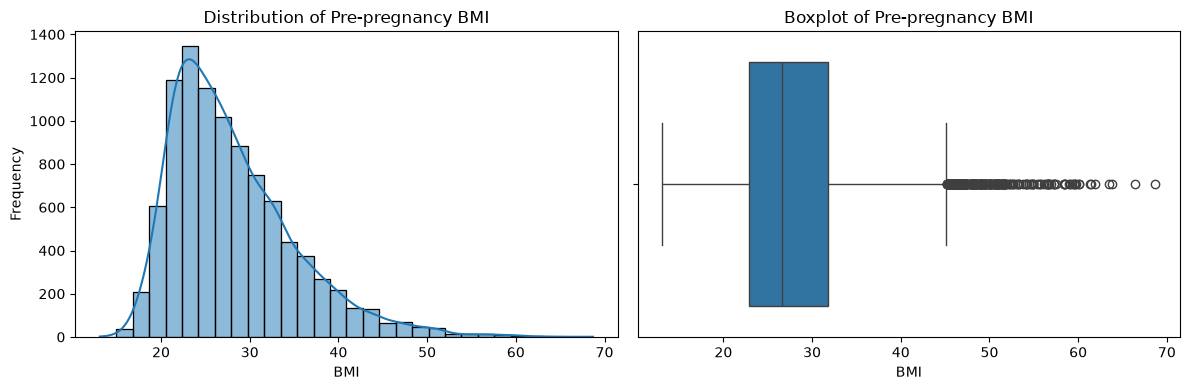

In [12]:
column = "prepregnancy_bmi"

Q1 = df[column].quantile(0.25)
Q3 = df[column].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df[column] < lower_bound) |
    (df[column] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nNumber of outliers:", len(outliers))
print("\nOutlier values:")
print(outliers[column].sort_values())
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df["prepregnancy_bmi"].dropna(), bins=30, kde=True)
plt.title("Distribution of Pre-pregnancy BMI")
plt.xlabel("BMI")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["prepregnancy_bmi"])
plt.title("Boxplot of Pre-pregnancy BMI")
plt.xlabel("BMI")

plt.tight_layout()
plt.show()

In [13]:
print("Number of outliers:", len(outliers))

print("\nOutlier statistics:")
print(outliers["prepregnancy_bmi"].describe())

print("\nOutlier frequencies:")
print(outliers["prepregnancy_bmi"].value_counts().sort_index())

print("\nBMI values above 60:")
print(
    df.loc[
        df["prepregnancy_bmi"] > 60,
        ["prepregnancy_bmi", "preterm_birth"]
    ]
)

Number of outliers: 262

Outlier statistics:
count    262.000000
mean      50.117176
std        4.383159
min       45.200000
25%       46.825000
50%       48.950000
75%       51.600000
max       68.700000
Name: prepregnancy_bmi, dtype: float64

Outlier frequencies:
prepregnancy_bmi
45.2    4
45.3    7
45.4    5
45.5    1
45.6    1
       ..
61.9    1
63.5    1
63.8    1
66.4    1
68.7    1
Name: count, Length: 107, dtype: int64

BMI values above 60:
      prepregnancy_bmi  preterm_birth
1476              60.1              0
2488              66.4              0
2816              61.4              0
5698              63.5              0
7474              61.9              0
7793              60.1              0
8786              61.3              0
9616              63.8              0
9976              68.7              1


### Outlier Analysis – Pre-pregnancy BMI

The IQR method identified 262 potential outliers (2.71% of
the 9,660 non-missing BMI observations).

- Lower bound: 9.55
- Upper bound: 45.15
- Outlier minimum: 45.2
- Outlier median: 48.95
- Outlier mean: 50.12
- Outlier maximum: 68.7

All detected outliers are above the upper bound. These values
are statistically unusual but are not confirmed data errors.

Nine observations have a BMI greater than 60. Eight have
preterm_birth = 0 and one has preterm_birth = 1. This small
subgroup is insufficient to support a reliable conclusion
about the relationship between BMI and preterm birth.

No outliers are removed at this EDA stage.

### 6. Pre-pregnancy Diabetes (`prepregnancy_diabetes`)

**Description:** Indicates whether the mother had diabetes
before pregnancy.

**Variable type:** Categorical (Nominal, Binary).

**Observed categories:** `no`, `yes`.

**Missing values:** 70 (0.70%).

**Distribution:**
- `no`: 9,773 (97.73%)
- `yes`: 157 (1.57%)

**Main observations:**
- The majority of observations are classified as `no`.
- The `yes` category is relatively rare.
- Missing values must not automatically be interpreted as `no`.

**Preprocessing consideration:**
This nominal categorical feature may be encoded using
One-Hot Encoding or a suitable binary encoding after
the train/test split. Missing-value handling must be
decided during preprocessing.

In [14]:
column = "prepregnancy_diabetes"

print("Data type:", df[column].dtype)

print("\nUnique values:")
print(df[column].unique())

print("\nValue counts (including missing):")
print(df[column].value_counts(dropna=False))

print("\nNumber of categories:")
print(df[column].nunique(dropna=False))

print("\nMissing values:")
print(df[column].isna().sum())

Data type: str

Unique values:
<StringArray>
['no', 'yes', nan]
Length: 3, dtype: str

Value counts (including missing):
prepregnancy_diabetes
no     9773
yes     157
NaN      70
Name: count, dtype: int64

Number of categories:
3

Missing values:
70


### 7. Pre-pregnancy Hypertension (`prepregnancy_hypertension`)

**Description:** Indicates whether the mother had hypertension
before pregnancy.

**Variable type:** Categorical (Nominal, Binary).

**Observed categories:** `no`, `yes`.

**Missing values:** 70 (0.70%).

**Distribution:**
- `no`: 9,377 (93.77%)
- `yes`: 553 (5.53%)

**Main observations:**
- Most observations are classified as `no`.
- The `yes` category is less frequent.
- Missing values must not automatically be interpreted as `no`.

**Preprocessing consideration:**
This nominal categorical feature may be encoded using
One-Hot Encoding or a suitable binary encoding after
the train/test split. Missing-value handling must be
decided during preprocessing.

In [15]:
column = "prepregnancy_hypertension"

print("Data type:", df[column].dtype)

print("\nUnique values:")
print(df[column].unique())

print("\nValue counts (including missing):")
print(df[column].value_counts(dropna=False))

print("\nNumber of categories:")
print(df[column].nunique(dropna=False))

print("\nMissing values:")
print(df[column].isna().sum())

Data type: str

Unique values:
<StringArray>
['no', 'yes', nan]
Length: 3, dtype: str

Value counts (including missing):
prepregnancy_hypertension
no     9377
yes     553
NaN      70
Name: count, dtype: int64

Number of categories:
3

Missing values:
70


### 8. Previous Preterm Birth (`previous_preterm_birth`)

**Description:** Indicates whether the mother had a previous
preterm birth.

**Variable type:** Categorical (Nominal, Binary).

**Observed categories:** `no`, `yes`.

**Missing values:** 70 (0.70%).

**Distribution:**
- `no`: 9,301 (93.01%)
- `yes`: 629 (6.29%)

**Main observations:**
- Most observations are classified as `no`.
- 629 observations report a previous preterm birth.
- Missing values must not automatically be interpreted as `no`.

**Preprocessing consideration:**
This nominal categorical feature may be encoded using
One-Hot Encoding or a suitable binary encoding after
the train/test split. Missing-value handling must be
decided during preprocessing.

In [16]:
column = "previous_preterm_birth"

print("Data type:", df[column].dtype)

print("\nUnique values:")
print(df[column].unique())

print("\nValue counts (including missing):")
print(df[column].value_counts(dropna=False))

print("\nNumber of categories:")
print(df[column].nunique(dropna=False))

print("\nMissing values:")
print(df[column].isna().sum())

Data type: str

Unique values:
<StringArray>
['no', 'yes', nan]
Length: 3, dtype: str

Value counts (including missing):
previous_preterm_birth
no     9301
yes     629
NaN      70
Name: count, dtype: int64

Number of categories:
3

Missing values:
70


### 9. Plurality (`plurality`)

**Description:** Number of babies in the pregnancy.

**Variable type:** Categorical (Ordinal).

**Observed categories:** `singleton`, `twins`, `triplets`.

**Missing values:** 0 (0%).

**Distribution:**
- `singleton`: 9,669 (96.69%)
- `twins`: 325 (3.25%)
- `triplets`: 6 (0.06%)

**Main observations:**
- Most pregnancies in the sample are singleton pregnancies.
- Twin pregnancies represent 3.25% of the observations.
- Only six observations are classified as triplets.
- No missing values were detected.

**Preprocessing consideration:**
The categories have a natural order based on the number of babies.
However, ordinal encoding should be selected carefully because
the numerical codes may imply equal spacing between categories.
The very small triplets group should be considered when evaluating
model performance.

In [17]:
column = "plurality"

print("Data type:", df[column].dtype)

print("\nUnique values:")
print(df[column].unique())

print("\nValue counts (including missing):")
print(df[column].value_counts(dropna=False))

print("\nNumber of categories:")
print(df[column].nunique(dropna=False))

print("\nMissing values:")
print(df[column].isna().sum())

Data type: str

Unique values:
<StringArray>
['singleton', 'twins', 'triplets']
Length: 3, dtype: str

Value counts (including missing):
plurality
singleton    9669
twins         325
triplets        6
Name: count, dtype: int64

Number of categories:
3

Missing values:
0


In [18]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

missing_report

,Missing_Count,Missing_Percentage
maternal_age_group,0,0.00
maternal_education,141,1.41
prior_live_births_now_living,77,0.77
prior_live_births_now_dead,384,3.84
prepregnancy_bmi,340,3.40
prepregnancy_diabetes,70,0.70
prepregnancy_hypertension,70,0.70
previous_preterm_birth,70,0.70
plurality,0,0.00
preterm_birth,0,0.00


In [19]:
missing_report = pd.DataFrame({
    "Feature": df.columns,
    "Missing_Count": df.isna().sum().values,
    "Missing_Percentage": (df.isna().mean() * 100).round(2).values
})

missing_report.to_csv("missing_values_report.csv", index=False)

print("Missing values report exported successfully!")
print(missing_report)

Missing values report exported successfully!
                        Feature  Missing_Count  Missing_Percentage
0            maternal_age_group              0                0.00
1            maternal_education            141                1.41
2  prior_live_births_now_living             77                0.77
3    prior_live_births_now_dead            384                3.84
4              prepregnancy_bmi            340                3.40
5         prepregnancy_diabetes             70                0.70
6     prepregnancy_hypertension             70                0.70
7        previous_preterm_birth             70                0.70
8                     plurality              0                0.00
9                 preterm_birth              0                0.00


In [20]:
rows_with_missing = df.isna().any(axis=1).sum()

print("Total rows:", len(df))
print("Rows with at least one missing value:", rows_with_missing)
print("Rows without missing values:", len(df) - rows_with_missing)
print(
    "Percentage of rows with missing values:",
    round(rows_with_missing / len(df) * 100, 2), "%"
)

Total rows: 10000
Rows with at least one missing value: 846
Rows without missing values: 9154
Percentage of rows with missing values: 8.46 %


## Global Missing Values Analysis

The dataset contains 10,000 observations and 10 features.

A total of 1,152 missing cells were identified,
representing 1.152% of all dataset cells.

Six features contain missing values. The highest
missing percentages are observed in:

- prior_live_births_now_dead: 3.84%
- prepregnancy_bmi: 3.40%
- maternal_education: 1.41%

The target variable (`preterm_birth`) contains no
missing values.

Missing values will be investigated and handled during
the preprocessing stage. No automatic replacement or
row deletion is performed during this EDA stage.

### Missing Values at Row Level

The dataset contains 10,000 observations.

- Rows with at least one missing value: 846 (8.46%).
- Rows without missing values: 9,154 (91.54%).
- Total missing cells: 1,152.

The number of rows with missing values is lower than
the total number of missing cells because some rows
contain missing values in multiple features.

No rows are removed at this stage.
Missing-value treatment will be performed during
the preprocessing phase.

In [21]:
# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)

# Calculate percentage
duplicate_percentage = (duplicate_count / len(df)) * 100

print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

Number of exact duplicate rows: 2025
Duplicate percentage: 20.25 %


In [22]:
# Display duplicate rows
duplicates = df[df.duplicated(keep=False)]

print("Total rows involved in duplicates:", len(duplicates))

duplicates.head(10)

Total rows involved in duplicates: 3264


,maternal_age_group,maternal_education,prior_live_births_now_living,prior_live_births_now_dead,prepregnancy_bmi,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,plurality,preterm_birth
0,20_24,high_school_or_GED,1.0,0.0,26.6,no,no,no,singleton,0
1,25_29,high_school_or_GED,2.0,0.0,28.3,no,no,no,singleton,0
6,25_29,masters_degree,1.0,0.0,25.1,no,no,no,singleton,0
8,30_34,some_college_no_degree,1.0,0.0,31.3,no,no,no,singleton,0
10,25_29,bachelor_degree,0.0,0.0,27.3,no,no,no,singleton,0
11,20_24,high_school_or_GED,0.0,0.0,29.0,no,no,no,singleton,0
14,30_34,bachelor_degree,1.0,0.0,23.3,no,no,no,singleton,0
15,25_29,high_school_or_GED,1.0,0.0,32.3,no,no,no,singleton,0
18,25_29,bachelor_degree,1.0,0.0,23.4,no,no,no,singleton,0
39,30_34,high_school_or_GED,1.0,0.0,31.1,no,no,no,singleton,0


In [23]:
# Features only, excluding the target
features = df.drop(columns=["preterm_birth"])

# Group identical feature combinations
groups = df.groupby(list(features.columns), dropna=False)

# Count groups with more than one target value
conflicting_groups = groups["preterm_birth"].nunique()

conflicting_groups = conflicting_groups[conflicting_groups > 1]

print("Number of feature combinations with conflicting targets:",
      len(conflicting_groups))

Number of feature combinations with conflicting targets: 224


In [24]:
# Frequency of each complete row
duplicate_groups = df.value_counts(dropna=False)

# Keep only rows appearing more than once
repeated_groups = duplicate_groups[duplicate_groups > 1]

print("Number of repeated unique rows:", len(repeated_groups))

print("\nFrequency of repeated rows:")
print(repeated_groups.value_counts().sort_index())

print("\nMost repeated observations:")
print(repeated_groups.sort_values(ascending=False).head(10))

Number of repeated unique rows: 1239

Frequency of repeated rows:
count
2     815
3     242
4      99
5      41
6      21
7       7
8       7
9       2
10      2
11      1
13      1
14      1
Name: count, dtype: int64

Most repeated observations:
maternal_age_group  maternal_education      prior_live_births_now_living  prior_live_births_now_dead  prepregnancy_bmi  prepregnancy_diabetes  prepregnancy_hypertension  previous_preterm_birth  plurality  preterm_birth
20_24               high_school_or_GED      0.0                           0.0                         26.6              no                     no                         no                      singleton  0                14
                                                                                                      NaN               no                     no                         no                      singleton  0                13
25_29               high_school_or_GED      1.0                           0.0       

### Duplicate Feature Combinations with Conflicting Targets

A further investigation was performed to identify identical
feature combinations associated with different target values.

The analysis identified 224 feature combinations with
conflicting target labels.

This means that identical recorded maternal characteristics
can be associated with both term and preterm births.

Possible explanations include:
- Different mothers sharing the same recorded characteristics.
- Relevant predictive factors not included in the dataset.
- Natural variability in pregnancy outcomes.

These observations are not automatically considered errors
and will not be removed during EDA.

In [25]:
duplicate_groups = df.value_counts(dropna=False)

repeated_groups = duplicate_groups[duplicate_groups > 1]

print("Number of repeated unique rows:", len(repeated_groups))

print("\nFrequency of repeated rows:")
print(repeated_groups.value_counts().sort_index())

print("\nMost repeated observations:")
print(repeated_groups.sort_values(ascending=False).head(10))

Number of repeated unique rows: 1239

Frequency of repeated rows:
count
2     815
3     242
4      99
5      41
6      21
7       7
8       7
9       2
10      2
11      1
13      1
14      1
Name: count, dtype: int64

Most repeated observations:
maternal_age_group  maternal_education      prior_live_births_now_living  prior_live_births_now_dead  prepregnancy_bmi  prepregnancy_diabetes  prepregnancy_hypertension  previous_preterm_birth  plurality  preterm_birth
20_24               high_school_or_GED      0.0                           0.0                         26.6              no                     no                         no                      singleton  0                14
                                                                                                      NaN               no                     no                         no                      singleton  0                13
25_29               high_school_or_GED      1.0                           0.0       

## Duplicate Rows Analysis

The dataset contains 10,000 observations.

- Exact duplicate rows (excluding first occurrences): 2,025.
- Rows involved in duplicate groups: 3,264.
- Number of repeated unique rows: 1,239.
- Duplicate percentage: 20.25%.

The frequency analysis shows that:
- 815 groups appear twice.
- 242 groups appear three times.
- The most repeated group appears 14 times.

A further investigation identified 224 feature combinations
associated with conflicting target values.

Identical recorded characteristics do not necessarily
represent the same individual.

Possible explanations include different individuals
sharing the same characteristics or limitations in
the available features.

No duplicate rows are automatically removed during EDA.
The sampling procedure and original data-generation
script should be investigated before making a decision.

In [26]:
column = "preterm_birth"

print("Data type:", df[column].dtype)

print("\nUnique values:")
print(df[column].unique())

print("\nValue counts:")
print(df[column].value_counts())

print("\nValue counts in percentage:")
print(
    (df[column].value_counts(normalize=True) * 100).round(2)
)

print("\nMissing values:")
print(df[column].isna().sum())

Data type: int64

Unique values:
[0 1]

Value counts:
preterm_birth
0    8938
1    1062
Name: count, dtype: int64

Value counts in percentage:
preterm_birth
0    89.38
1    10.62
Name: proportion, dtype: float64

Missing values:
0


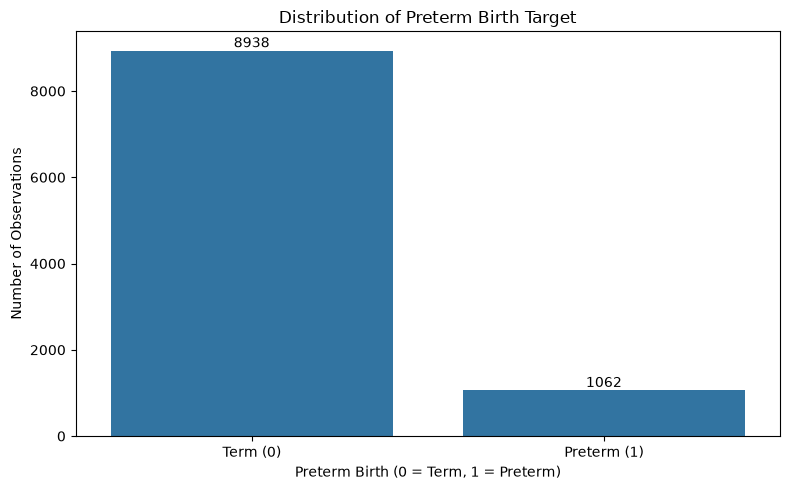

In [29]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x="preterm_birth")

plt.title("Distribution of Preterm Birth Target")
plt.xlabel("Preterm Birth (0 = Term, 1 = Preterm)")
plt.ylabel("Number of Observations")
plt.xticks([0, 1], ["Term (0)", "Preterm (1)"])

# Display the count and percentage above each bar
total = len(df)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()

# Save the figure
plt.savefig("target_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

### Target Variable Distribution

The target variable `preterm_birth` is a binary variable with two classes:

- `0`: Term birth (delivery at or after 37 completed weeks).
- `1`: Preterm birth (delivery before 37 completed weeks).

The dataset contains 8,938 term births (89.38%) and 1,062 preterm births (10.62%). No missing values were found in the target variable.

The target distribution is imbalanced because the majority class (term births) represents 89.38% of the observations, while the minority class (preterm births) represents only 10.62%.

This class imbalance is important for model development and evaluation. Accuracy alone may be misleading, so additional metrics such as recall, precision, F1-score, and the confusion matrix should be considered.

No resampling or balancing technique will be applied during EDA. These decisions will be considered later during model development.

In [30]:
age_target = pd.crosstab(
    df["maternal_age_group"],
    df["preterm_birth"]
)

age_target

preterm_birth,0,1
maternal_age_group,,
15,6,1
16,18,2
17,48,7
18,86,7
19,167,23
20_24,1766,201
25_29,2566,283
30_34,2516,273
35_39,1436,213


In [31]:
age_target_percentage = pd.crosstab(
    df["maternal_age_group"],
    df["preterm_birth"],
    normalize="index"
) * 100

age_target_percentage.round(2)

preterm_birth,0,1
maternal_age_group,,
15,85.71,14.29
16,90.00,10.00
17,87.27,12.73
18,92.47,7.53
19,87.89,12.11
20_24,89.78,10.22
25_29,90.07,9.93
30_34,90.21,9.79
35_39,87.08,12.92


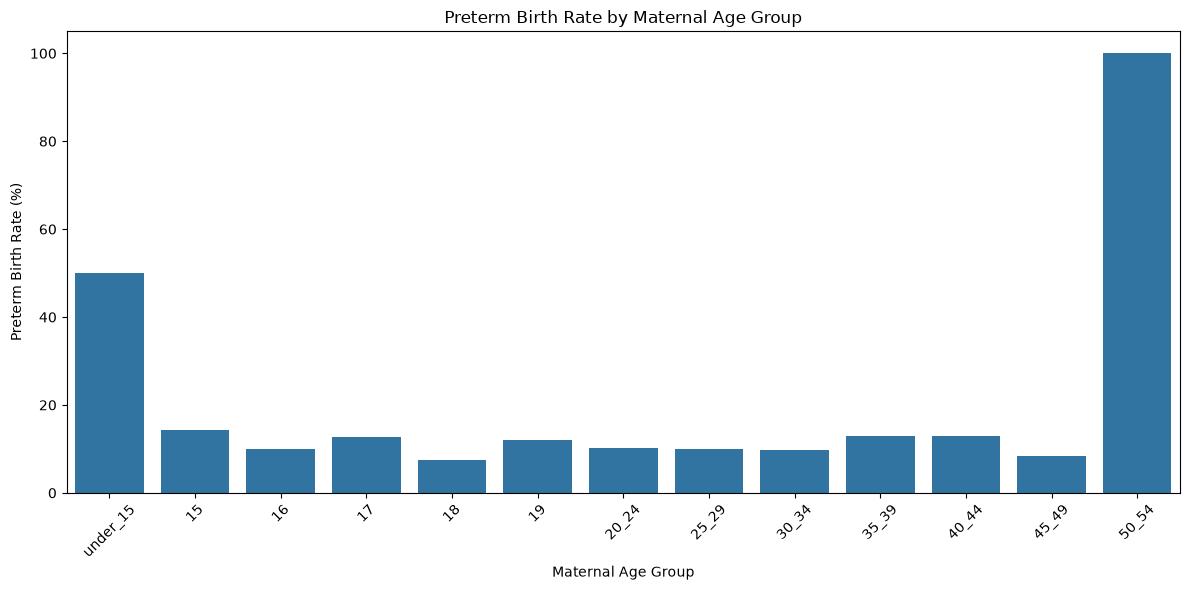

In [32]:
# Calculate preterm birth percentage by maternal age group
preterm_rate_by_age = (
    df.groupby("maternal_age_group", observed=False)["preterm_birth"]
    .mean() * 100
)

# Sort age groups for a clearer visualization
age_order = [
    "under_15", "15", "16", "17", "18", "19",
    "20_24", "25_29", "30_34", "35_39",
    "40_44", "45_49", "50_54"
]

preterm_rate_by_age = preterm_rate_by_age.reindex(age_order)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=preterm_rate_by_age.index,
    y=preterm_rate_by_age.values
)

plt.title("Preterm Birth Rate by Maternal Age Group")
plt.xlabel("Maternal Age Group")
plt.ylabel("Preterm Birth Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Relationship Between Maternal Age and Preterm Birth

A cross-tabulation was used to examine the relationship between maternal age groups and the target variable `preterm_birth`.

The percentage analysis shows that the preterm birth rate varies across maternal age groups.

Among the groups with relatively large sample sizes, the highest observed rates were in the 40–44 age group (12.95%) and the 35–39 age group (12.92%). In comparison, the 25–29 and 30–34 age groups had lower rates of 9.93% and 9.79%, respectively.

Some groups, such as 50–54 and under 15, show extreme percentages. However, these groups contain very few observations (2 and 4 observations, respectively). Therefore, their percentages should be interpreted with caution.

These results describe associations in the dataset and do not establish a causal relationship between maternal age and preterm birth.

In [33]:
education_target = pd.crosstab(
    df["maternal_education"],
    df["preterm_birth"]
)

education_target

preterm_birth,0,1
maternal_education,,
associate_degree,666,73
bachelor_degree,1724,145
doctorate_or_professional_degree,242,19
grade_8_or_less,75,11
grade_9_to_12_no_diploma,594,121
high_school_or_GED,2976,384
masters_degree,656,66
some_college_no_degree,1887,220


In [34]:
education_target_percentage = pd.crosstab(
    df["maternal_education"],
    df["preterm_birth"],
    normalize="index"
) * 100

education_target_percentage.round(2)

preterm_birth,0,1
maternal_education,,
associate_degree,90.12,9.88
bachelor_degree,92.24,7.76
doctorate_or_professional_degree,92.72,7.28
grade_8_or_less,87.21,12.79
grade_9_to_12_no_diploma,83.08,16.92
high_school_or_GED,88.57,11.43
masters_degree,90.86,9.14
some_college_no_degree,89.56,10.44


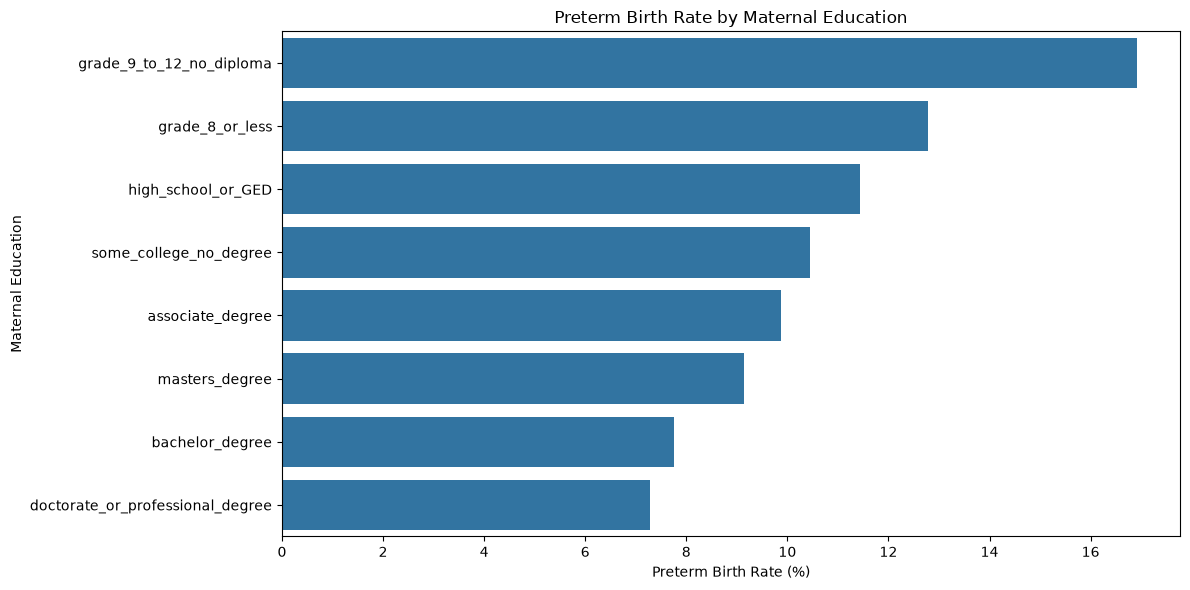

In [35]:
education_preterm_rate = (
    df.groupby("maternal_education", observed=False)["preterm_birth"]
    .mean() * 100
)

education_preterm_rate = education_preterm_rate.sort_values(
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=education_preterm_rate.values,
    y=education_preterm_rate.index
)

plt.title("Preterm Birth Rate by Maternal Education")
plt.xlabel("Preterm Birth Rate (%)")
plt.ylabel("Maternal Education")

plt.tight_layout()
plt.savefig(
    "preterm_rate_by_education.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Relationship Between Maternal Education and Preterm Birth

A cross-tabulation was performed to examine the relationship between maternal education and the target variable `preterm_birth`.

The results show differences in preterm birth rates across educational categories.

The highest observed rate was found among mothers with some high school education but no diploma (16.92%). The group with grade 8 education or less also showed a relatively high rate (12.79%).

In comparison, mothers with a bachelor's degree and those with a doctorate or professional degree had lower observed rates of 7.76% and 7.28%, respectively.

These findings suggest an association between maternal education and preterm birth in this dataset. However, they do not establish causation. Other factors, such as socioeconomic conditions and access to healthcare, may also be relevant.

The results should be interpreted descriptively and do not imply that maternal education directly causes or prevents preterm birth.

In [37]:
living_births_target = pd.crosstab(
    df["prior_live_births_now_living"],
    df["preterm_birth"]
)

living_births_target

preterm_birth,0,1
prior_live_births_now_living,,
0.0,3320,365
1.0,2547,261
2.0,1494,182
3.0,759,108
4.0,379,58
5.0,174,40
6.0,101,24
7.0,46,12
8.0,22,1


In [38]:
living_births_target_percentage = pd.crosstab(
    df["prior_live_births_now_living"],
    df["preterm_birth"],
    normalize="index"
) * 100

living_births_target_percentage.round(2)

preterm_birth,0,1
prior_live_births_now_living,,
0.0,90.09,9.91
1.0,90.71,9.29
2.0,89.14,10.86
3.0,87.54,12.46
4.0,86.73,13.27
5.0,81.31,18.69
6.0,80.80,19.20
7.0,79.31,20.69
8.0,95.65,4.35


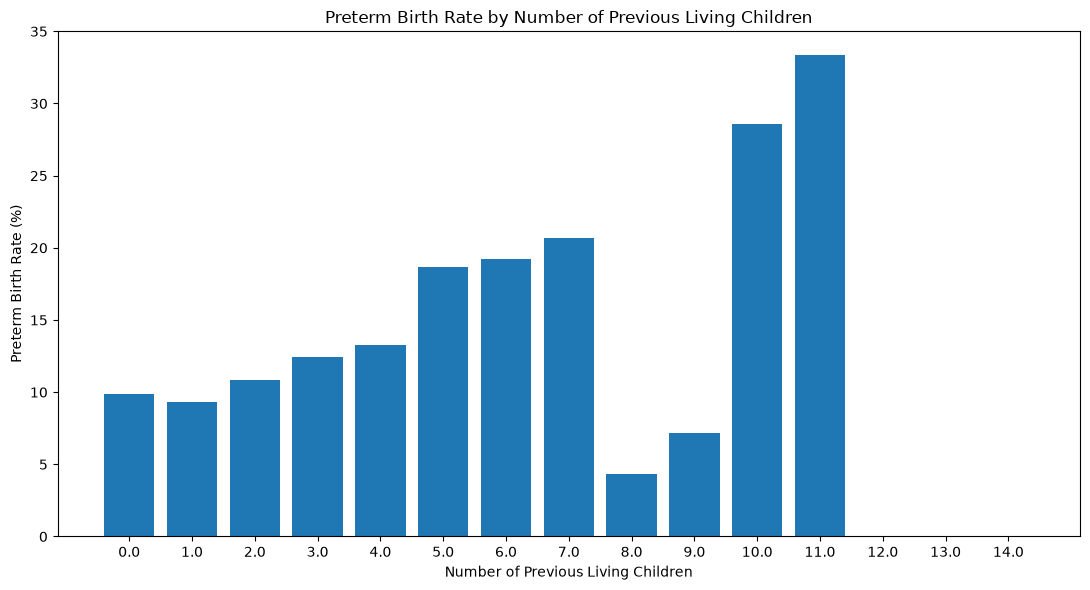

In [39]:
living_births_rate = (
    df.groupby("prior_live_births_now_living")["preterm_birth"]
    .mean() * 100
)

living_births_count = (
    df.groupby("prior_live_births_now_living")["preterm_birth"]
    .count()
)

plt.figure(figsize=(11, 6))

plt.bar(
    living_births_rate.index.astype(str),
    living_births_rate.values
)

plt.title("Preterm Birth Rate by Number of Previous Living Children")
plt.xlabel("Number of Previous Living Children")
plt.ylabel("Preterm Birth Rate (%)")

plt.tight_layout()

plt.savefig(
    "preterm_rate_by_previous_living_children.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Relationship Between Previous Living Children and Preterm Birth

A cross-tabulation was performed to examine the relationship between `prior_live_births_now_living` and the target variable `preterm_birth`.

The results show that the observed preterm birth rate generally increases across several groups with higher numbers of previous living children. For example, the rate was 9.91% among mothers with no previous living children, compared with 12.46% among those with three and 19.20% among those with six.

However, this pattern should be interpreted cautiously. The number of observations decreases considerably in groups with higher counts. For example, the group with 11 previous living children contains only three observations, making its estimated rate unstable.

These findings describe an association in the dataset and do not establish a causal relationship. Further analysis would be needed to account for other maternal and pregnancy-related factors.

In [40]:
dead_births_target = pd.crosstab(
    df["prior_live_births_now_dead"],
    df["preterm_birth"]
)

dead_births_target

preterm_birth,0,1
prior_live_births_now_dead,,
0.0,8434,1006
1.0,111,28
2.0,21,4
3.0,4,2
4.0,2,1
5.0,1,1
9.0,1,0


In [41]:
dead_births_target_percentage = pd.crosstab(
    df["prior_live_births_now_dead"],
    df["preterm_birth"],
    normalize="index"
) * 100

dead_births_target_percentage.round(2)

preterm_birth,0,1
prior_live_births_now_dead,,
0.0,89.34,10.66
1.0,79.86,20.14
2.0,84.00,16.00
3.0,66.67,33.33
4.0,66.67,33.33
5.0,50.00,50.00
9.0,100.00,0.00


In [42]:
print("Frequency of each value:")
print(df["prior_live_births_now_dead"].value_counts(dropna=False).sort_index())

print("\nRows where the value is 9:")
df[df["prior_live_births_now_dead"] == 9]

Frequency of each value:
prior_live_births_now_dead
0.0    9440
1.0     139
2.0      25
3.0       6
4.0       3
5.0       2
9.0       1
NaN     384
Name: count, dtype: int64

Rows where the value is 9:


,maternal_age_group,maternal_education,prior_live_births_now_living,prior_live_births_now_dead,prepregnancy_bmi,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,plurality,preterm_birth
31,35_39,masters_degree,2.0,9.0,NaN,no,no,no,singleton,0


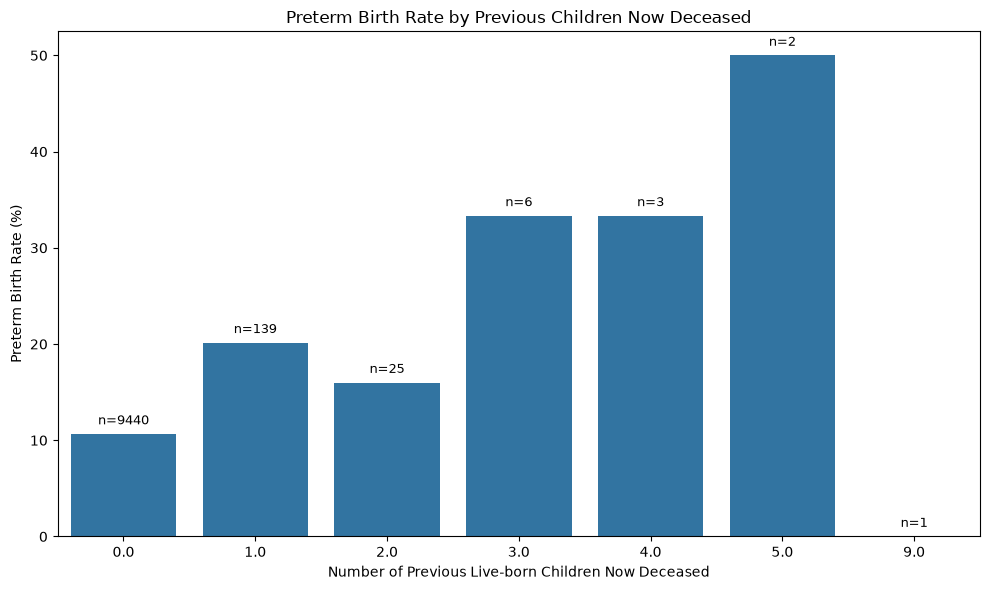

In [43]:
dead_births_analysis = df.groupby(
    "prior_live_births_now_dead"
)["preterm_birth"].agg(["count", "mean"])

dead_births_analysis["preterm_rate"] = (
    dead_births_analysis["mean"] * 100
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=dead_births_analysis.index.astype(str),
    y=dead_births_analysis["preterm_rate"]
)

plt.title("Preterm Birth Rate by Previous Children Now Deceased")
plt.xlabel("Number of Previous Live-born Children Now Deceased")
plt.ylabel("Preterm Birth Rate (%)")

for i, row in enumerate(dead_births_analysis.itertuples()):
    ax.text(
        i,
        row.preterm_rate + 1,
        f"n={row.count}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "preterm_rate_by_previous_children_deceased.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship Between Previous Live-born Children Now Deceased and Preterm Birth

A cross-tabulation was performed to examine the relationship between `prior_live_births_now_dead` and the target variable `preterm_birth`.

Most observations (9,440) had a value of zero for this feature. Among these observations, the preterm birth rate was 10.66%.

The group with one previous live-born child now deceased showed a preterm birth rate of 20.14%. Higher percentages were also observed in some groups with larger values. However, these groups contained very few observations, making their percentages unstable and difficult to interpret.

One observation had a value of 9. This value requires verification against the official CDC data documentation before its meaning can be determined.

The feature also contains 384 missing values (3.84% of the full dataset). Missing values were not treated as zero.

These findings are descriptive and do not establish a causal relationship between this feature and preterm birth.

In [44]:
bmi_target_analysis = df.groupby("preterm_birth")[
    "prepregnancy_bmi"
].describe()

bmi_target_analysis

,count,mean,std,min,25%,50%,75%,max
preterm_birth,,,,,,,,
0,8622.0,27.997472,6.948120,13.1,22.9,26.6,31.8,66.4
1,1038.0,28.667919,7.438443,14.6,23.2,27.3,32.8,68.7


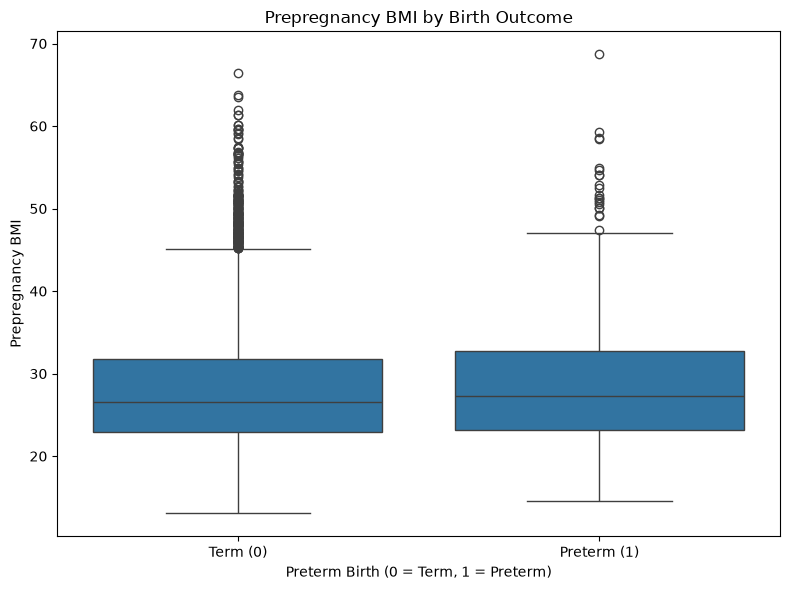

In [45]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="preterm_birth",
    y="prepregnancy_bmi"
)

plt.title("Prepregnancy BMI by Birth Outcome")
plt.xlabel("Preterm Birth (0 = Term, 1 = Preterm)")
plt.ylabel("Prepregnancy BMI")

plt.xticks([0, 1], ["Term (0)", "Preterm (1)"])

plt.tight_layout()
plt.show()

### Relationship Between Prepregnancy BMI and Preterm Birth

Descriptive statistics were calculated to compare prepregnancy BMI between term and preterm birth groups.

The mean BMI was 27.997 for term births and 28.668 for preterm births. Similarly, the median BMI was 26.6 for term births and 27.3 for preterm births.

The standard deviation was slightly higher in the preterm group (7.438) than in the term group (6.948), indicating somewhat greater variability.

Overall, the preterm group showed slightly higher mean and median BMI values. However, the differences were modest and do not establish a causal relationship between prepregnancy BMI and preterm birth.

The analysis was based on 9,660 non-missing BMI observations. The remaining 340 observations were missing and were not included in these group-specific descriptive statistics.

Further analysis is needed to assess the relationship while considering other maternal and pregnancy-related variables.

In [46]:
diabetes_target = pd.crosstab(
    df["prepregnancy_diabetes"],
    df["preterm_birth"]
)

diabetes_target

preterm_birth,0,1
prepregnancy_diabetes,,
no,8782,991
yes,102,55


In [47]:
diabetes_target_percentage = pd.crosstab(
    df["prepregnancy_diabetes"],
    df["preterm_birth"],
    normalize="index"
) * 100

diabetes_target_percentage.round(2)

preterm_birth,0,1
prepregnancy_diabetes,,
no,89.86,10.14
yes,64.97,35.03


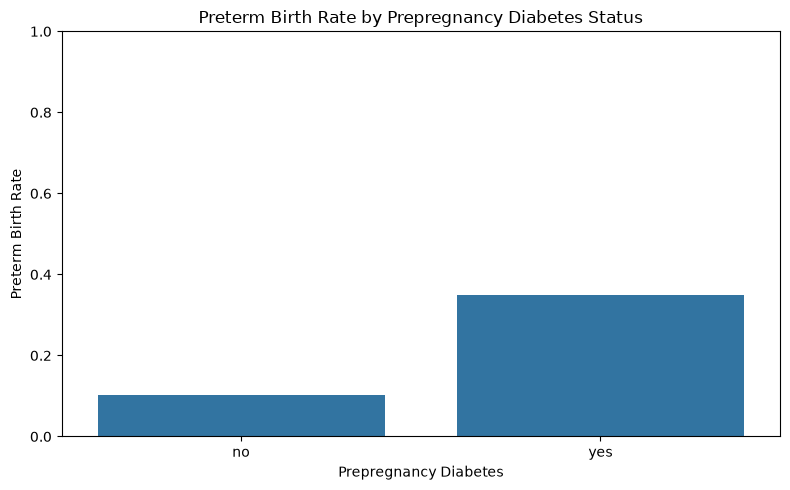

In [48]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="prepregnancy_diabetes",
    y="preterm_birth",
    errorbar=None
)

plt.title("Preterm Birth Rate by Prepregnancy Diabetes Status")
plt.xlabel("Prepregnancy Diabetes")
plt.ylabel("Preterm Birth Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("preterm_rate_by_diabetes.png", dpi=300, bbox_inches="tight")
plt.show()

### Relationship Between Prepregnancy Diabetes and Preterm Birth

The analysis shows a noticeable difference in preterm birth rates according to prepregnancy diabetes status.

- Among mothers without prepregnancy diabetes, **10.14%** of births were preterm.
- Among mothers with prepregnancy diabetes, **35.03%** of births were preterm.

This represents a difference of approximately **24.89 percentage points**. In this dataset, mothers with prepregnancy diabetes have a higher observed proportion of preterm births.

However, this finding indicates an association, not a causal relationship. The diabetic group contains only 157 observations, compared with 9,773 observations in the non-diabetic group. Therefore, the results should be interpreted cautiously.

In [49]:
hypertension_target = pd.crosstab(
    df["prepregnancy_hypertension"],
    df["preterm_birth"]
)

hypertension_target

preterm_birth,0,1
prepregnancy_hypertension,,
no,8447,930
yes,437,116


In [50]:
hypertension_target_percentage = pd.crosstab(
    df["prepregnancy_hypertension"],
    df["preterm_birth"],
    normalize="index"
) * 100

hypertension_target_percentage.round(2)

preterm_birth,0,1
prepregnancy_hypertension,,
no,90.08,9.92
yes,79.02,20.98


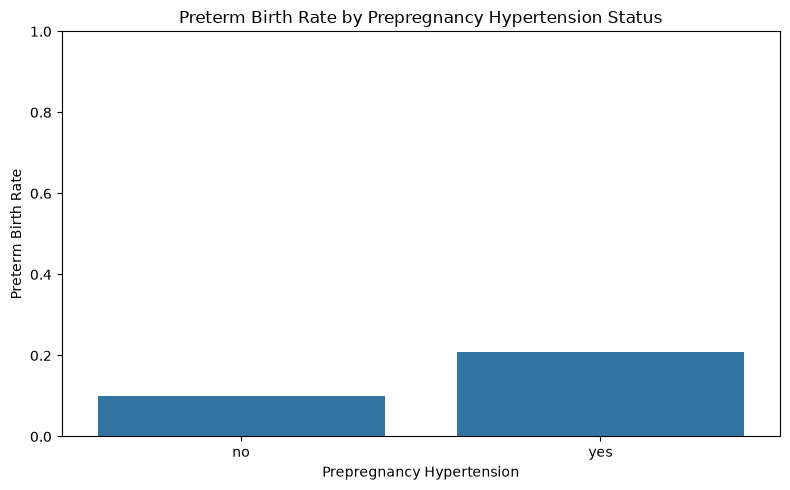

In [51]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="prepregnancy_hypertension",
    y="preterm_birth",
    errorbar=None
)

plt.title("Preterm Birth Rate by Prepregnancy Hypertension Status")
plt.xlabel("Prepregnancy Hypertension")
plt.ylabel("Preterm Birth Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("preterm_rate_by_hypertension.png", dpi=300, bbox_inches="tight")
plt.show()

### Relationship Between Prepregnancy Hypertension and Preterm Birth

The analysis reveals a difference in preterm birth rates according to prepregnancy hypertension status.

- Among mothers without prepregnancy hypertension, **9.92%** of births were preterm.
- Among mothers with prepregnancy hypertension, **20.98%** of births were preterm.

This represents a difference of approximately **11.06 percentage points**. In this dataset, mothers with prepregnancy hypertension have a higher observed proportion of preterm births.

However, this finding indicates an association rather than a causal relationship. The hypertension group contains 553 observations, compared with 9,377 observations in the non-hypertension group. The results should therefore be interpreted with caution.

In [52]:
previous_preterm_target = pd.crosstab(
    df["previous_preterm_birth"],
    df["preterm_birth"]
)

previous_preterm_target

preterm_birth,0,1
previous_preterm_birth,,
no,8474,827
yes,410,219


In [53]:
previous_preterm_percentage = pd.crosstab(
    df["previous_preterm_birth"],
    df["preterm_birth"],
    normalize="index"
) * 100

previous_preterm_percentage.round(2)

preterm_birth,0,1
previous_preterm_birth,,
no,91.11,8.89
yes,65.18,34.82


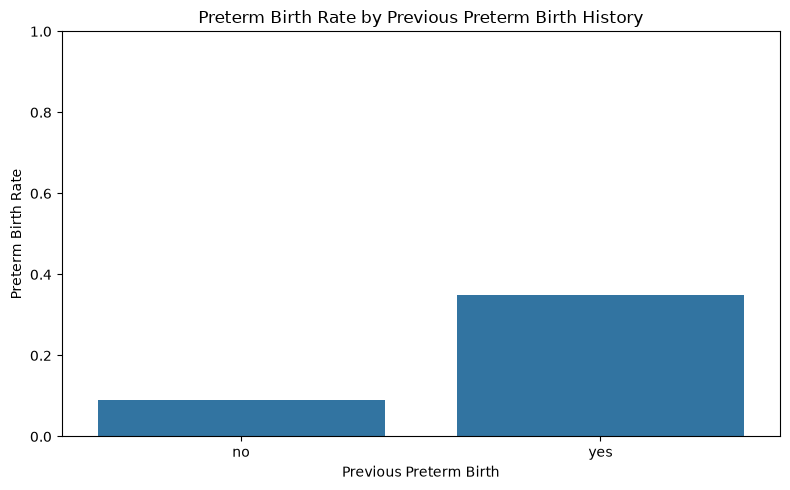

In [54]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="previous_preterm_birth",
    y="preterm_birth",
    errorbar=None
)

plt.title("Preterm Birth Rate by Previous Preterm Birth History")
plt.xlabel("Previous Preterm Birth")
plt.ylabel("Preterm Birth Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("preterm_rate_by_previous_preterm_birth.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Relationship Between Previous Preterm Birth and Current Preterm Birth

The analysis shows a substantial difference in preterm birth rates according to the mother's history of previous preterm birth.

- Among mothers with no history of previous preterm birth, **8.89%** of births were preterm.
- Among mothers with a history of previous preterm birth, **34.82%** of births were preterm.

This represents a difference of approximately **25.93 percentage points**. In this dataset, a history of previous preterm birth is associated with a higher observed proportion of preterm births.

This variable may be particularly informative for the prediction task. However, the observed association does not establish causation.

In [55]:
plurality_target = pd.crosstab(
    df["plurality"],
    df["preterm_birth"]
)

plurality_target

preterm_birth,0,1
plurality,,
singleton,8810,859
triplets,0,6
twins,128,197


In [56]:
plurality_percentage = pd.crosstab(
    df["plurality"],
    df["preterm_birth"],
    normalize="index"
) * 100

plurality_percentage.round(2)

preterm_birth,0,1
plurality,,
singleton,91.12,8.88
triplets,0.00,100.00
twins,39.38,60.62


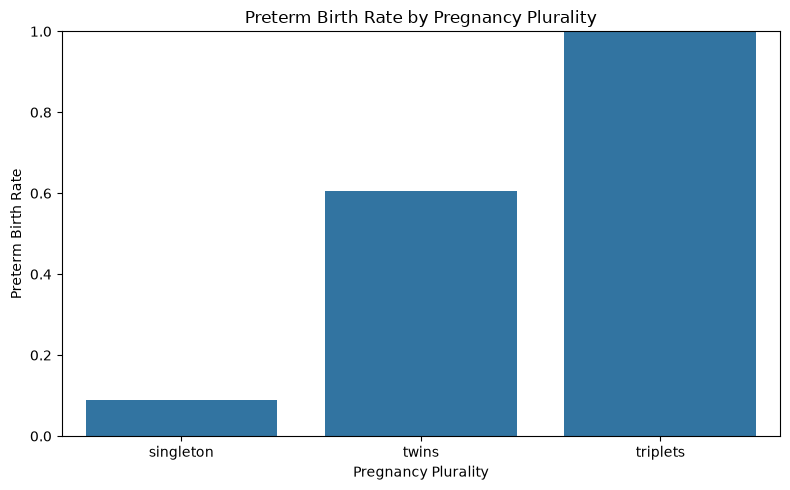

In [57]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="plurality",
    y="preterm_birth",
    order=["singleton", "twins", "triplets"],
    errorbar=None
)

plt.title("Preterm Birth Rate by Pregnancy Plurality")
plt.xlabel("Pregnancy Plurality")
plt.ylabel("Preterm Birth Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("preterm_rate_by_plurality.png", dpi=300, bbox_inches="tight")
plt.show()

### Relationship Between Plurality and Preterm Birth

The analysis reveals a substantial difference in preterm birth rates according to the number of babies in the pregnancy.

- Among singleton pregnancies, **8.88%** of births were preterm.
- Among twin pregnancies, **60.62%** of births were preterm.
- Among triplet pregnancies, **100%** of births were preterm.

The difference between singleton and twin pregnancies is approximately **51.74 percentage points**. In this dataset, twin pregnancies show a considerably higher observed proportion of preterm births than singleton pregnancies.

However, the triplet group contains only 6 observations, so its 100% rate should be interpreted with extreme caution. These findings describe associations in the dataset and do not establish causation.

In [58]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget distribution:")
print(df["preterm_birth"].value_counts())

Dataset shape: (10000, 10)

Data types:
maternal_age_group                  str
maternal_education                  str
prior_live_births_now_living    float64
prior_live_births_now_dead      float64
prepregnancy_bmi                float64
prepregnancy_diabetes               str
prepregnancy_hypertension           str
previous_preterm_birth              str
plurality                           str
preterm_birth                     int64
dtype: object

Missing values:
maternal_age_group                0
maternal_education              141
prior_live_births_now_living     77
prior_live_births_now_dead      384
prepregnancy_bmi                340
prepregnancy_diabetes            70
prepregnancy_hypertension        70
previous_preterm_birth           70
plurality                         0
preterm_birth                     0
dtype: int64

Duplicate rows:
2025

Target distribution:
preterm_birth
0    8938
1    1062
Name: count, dtype: int64


In [59]:
feature_dictionary = pd.DataFrame([
    {
        "Feature": "maternal_age_group",
        "Description": "Mother's age group at delivery",
        "Data_Type": "Categorical",
        "Feature_Type": "Ordinal",
        "Role": "Input",
        "Encoding_Consideration": "Ordinal encoding; preserve age-group order",
    },
    {
        "Feature": "maternal_education",
        "Description": "Mother's educational attainment",
        "Data_Type": "Categorical",
        "Feature_Type": "Ordinal",
        "Role": "Input",
        "Encoding_Consideration": "Ordinal encoding; preserve education order",
    },
    {
        "Feature": "prior_live_births_now_living",
        "Description": "Number of previous live-born children still living",
        "Data_Type": "Numerical",
        "Feature_Type": "Discrete",
        "Role": "Input",
        "Encoding_Consideration": "Numerical count; investigate missing values",
    },
    {
        "Feature": "prior_live_births_now_dead",
        "Description": "Number of previous live-born children now deceased",
        "Data_Type": "Numerical",
        "Feature_Type": "Discrete",
        "Role": "Input",
        "Encoding_Consideration": "Verify special value 9 using the official codebook",
    },
    {
        "Feature": "prepregnancy_bmi",
        "Description": "Mother's body mass index before pregnancy",
        "Data_Type": "Numerical",
        "Feature_Type": "Continuous",
        "Role": "Input",
        "Encoding_Consideration": "Investigate missing values and potential outliers",
    },
    {
        "Feature": "prepregnancy_diabetes",
        "Description": "Whether the mother had diabetes before pregnancy",
        "Data_Type": "Categorical",
        "Feature_Type": "Binary Nominal",
        "Role": "Input",
        "Encoding_Consideration": "One-Hot encoding; preserve missing values",
    },
    {
        "Feature": "prepregnancy_hypertension",
        "Description": "Whether the mother had hypertension before pregnancy",
        "Data_Type": "Categorical",
        "Feature_Type": "Binary Nominal",
        "Role": "Input",
        "Encoding_Consideration": "One-Hot encoding; preserve missing values",
    },
    {
        "Feature": "previous_preterm_birth",
        "Description": "Whether the mother had a previous preterm birth",
        "Data_Type": "Categorical",
        "Feature_Type": "Binary Nominal",
        "Role": "Input",
        "Encoding_Consideration": "One-Hot encoding; preserve missing values",
    },
    {
        "Feature": "plurality",
        "Description": "Number of babies in the pregnancy",
        "Data_Type": "Categorical",
        "Feature_Type": "Categorical",
        "Role": "Input",
        "Encoding_Consideration": "One-Hot encoding; categories are singleton, twins, triplets",
    },
    {
        "Feature": "preterm_birth",
        "Description": "Whether delivery occurred before 37 completed weeks",
        "Data_Type": "Numerical",
        "Feature_Type": "Binary",
        "Role": "Target",
        "Encoding_Consideration": "0 = Term; 1 = Preterm",
    }
])

# Add missing-value information directly from the dataset
feature_dictionary["Missing_Count"] = (
    feature_dictionary["Feature"].map(df.isnull().sum())
)

feature_dictionary["Missing_Percentage"] = (
    feature_dictionary["Feature"]
    .map((df.isnull().mean() * 100).round(2))
)

# Save the dictionary
feature_dictionary.to_csv("feature_dictionary.csv", index=False)

feature_dictionary

,Feature,Description,Data_Type,Feature_Type,Role,Encoding_Consideration,Missing_Count,Missing_Percentage
0,maternal_age_group,Mother's age group at delivery,Categorical,Ordinal,Input,Ordinal encoding; preserve age-group order,0,0.00
1,maternal_education,Mother's educational attainment,Categorical,Ordinal,Input,Ordinal encoding; preserve education order,141,1.41
2,prior_live_births_now_living,Number of previous live-born children still li...,Numerical,Discrete,Input,Numerical count; investigate missing values,77,0.77
3,prior_live_births_now_dead,Number of previous live-born children now dece...,Numerical,Discrete,Input,Verify special value 9 using the official code...,384,3.84
4,prepregnancy_bmi,Mother's body mass index before pregnancy,Numerical,Continuous,Input,Investigate missing values and potential outliers,340,3.40
5,prepregnancy_diabetes,Whether the mother had diabetes before pregnancy,Categorical,Binary Nominal,Input,One-Hot encoding; preserve missing values,70,0.70
6,prepregnancy_hypertension,Whether the mother had hypertension before pre...,Categorical,Binary Nominal,Input,One-Hot encoding; preserve missing values,70,0.70
7,previous_preterm_birth,Whether the mother had a previous preterm birth,Categorical,Binary Nominal,Input,One-Hot encoding; preserve missing values,70,0.70
8,plurality,Number of babies in the pregnancy,Categorical,Categorical,Input,"One-Hot encoding; categories are singleton, tw...",0,0.00
9,preterm_birth,Whether delivery occurred before 37 completed ...,Numerical,Binary,Target,0 = Term; 1 = Preterm,0,0.00


In [60]:
import os

print(os.path.exists("feature_dictionary.csv"))

True


In [61]:
detailed_descriptions = {
    "maternal_age_group":
        "Represents the mother's age group at the time of delivery. "
        "It is recorded using age intervals or individual age categories, "
        "allowing the analysis of maternal age in relation to preterm birth.",

    "maternal_education":
        "Indicates the highest level of educational attainment completed "
        "by the mother. Categories range from lower educational levels, "
        "such as grade 8 or less, to higher education, including master's "
        "and doctoral or professional degrees.",

    "prior_live_births_now_living":
        "Represents the total number of the mother's previous children "
        "who were born alive and are still living at the time of the "
        "current delivery. It is a discrete count and does not include "
        "the baby in the current pregnancy.",

    "prior_live_births_now_dead":
        "Represents the number of the mother's previous children who "
        "were born alive but are no longer living at the time of the "
        "current delivery. It excludes stillbirths. The special value "
        "9 requires verification using the original data codebook.",

    "prepregnancy_bmi":
        "Represents the mother's Body Mass Index (BMI) before the "
        "beginning of the current pregnancy. BMI is a numerical measure "
        "calculated from weight and height and is commonly used to "
        "describe body weight relative to height.",

    "prepregnancy_diabetes":
        "Indicates whether the mother had diabetes before the beginning "
        "of the current pregnancy. It is recorded as a binary categorical "
        "variable with two observed categories: Yes and No.",

    "prepregnancy_hypertension":
        "Indicates whether the mother had hypertension before the "
        "beginning of the current pregnancy. It helps examine the "
        "relationship between pre-existing maternal hypertension "
        "and preterm birth.",

    "previous_preterm_birth":
        "Indicates whether the mother had experienced at least one "
        "preterm birth in a previous pregnancy. It represents the "
        "mother's history of preterm delivery before the current pregnancy.",

    "plurality":
        "Describes the number of babies in the current pregnancy. "
        "It distinguishes singleton pregnancies (one baby), twin "
        "pregnancies (two babies), and triplet pregnancies (three babies).",

    "preterm_birth":
        "Represents the target variable indicating whether the current "
        "delivery occurred before 37 completed weeks of gestation. "
        "It is binary: 0 represents a term birth, while 1 represents "
        "a preterm birth."
}

feature_dictionary["Description"] = (
    feature_dictionary["Feature"].map(detailed_descriptions)
)

feature_dictionary.to_csv("feature_dictionary.csv", index=False)

feature_dictionary[["Feature", "Description"]]

,Feature,Description
0,maternal_age_group,Represents the mother's age group at the time ...
1,maternal_education,Indicates the highest level of educational att...
2,prior_live_births_now_living,Represents the total number of the mother's pr...
3,prior_live_births_now_dead,Represents the number of the mother's previous...
4,prepregnancy_bmi,Represents the mother's Body Mass Index (BMI) ...
5,prepregnancy_diabetes,Indicates whether the mother had diabetes befo...
6,prepregnancy_hypertension,Indicates whether the mother had hypertension ...
7,previous_preterm_birth,Indicates whether the mother had experienced a...
8,plurality,Describes the number of babies in the current ...
9,preterm_birth,Represents the target variable indicating whet...


In [62]:
print(
    "Missing descriptions:",
    feature_dictionary["Description"].isna().sum()
)

Missing descriptions: 0


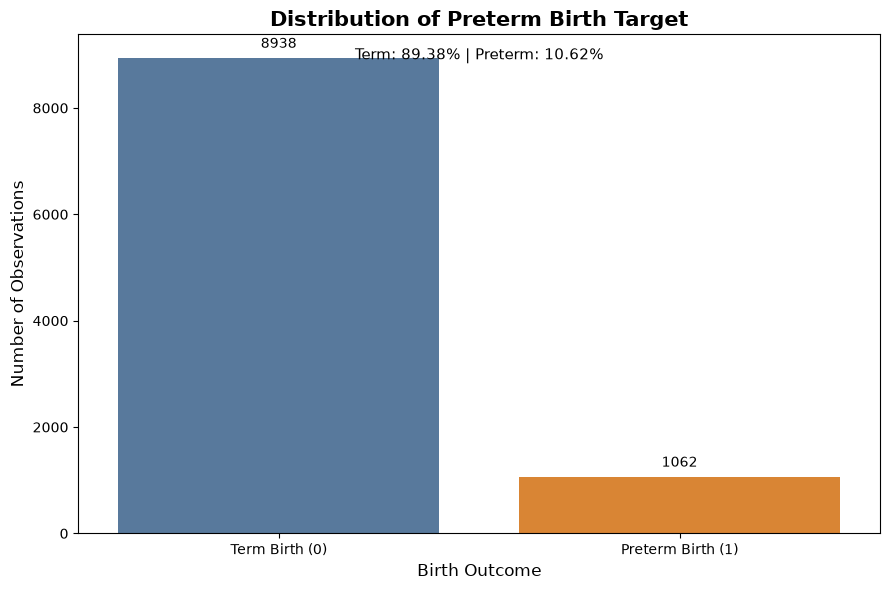

In [63]:
plt.figure(figsize=(9, 6))

ax = sns.countplot(
    data=df,
    x="preterm_birth",
    hue="preterm_birth",
    order=[0, 1],
    palette=["#4C78A8", "#F58518"],
    legend=False
)

plt.title("Distribution of Preterm Birth Target",
          fontsize=15, fontweight="bold")

plt.xlabel("Birth Outcome", fontsize=12)
plt.ylabel("Number of Observations", fontsize=12)

plt.xticks([0, 1], ["Term Birth (0)", "Preterm Birth (1)"])

total = len(df)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=5)

plt.text(
    0.5, 0.95,
    "Term: 89.38% | Preterm: 10.62%",
    transform=plt.gca().transAxes,
    ha="center",
    fontsize=11
)

plt.tight_layout()

plt.savefig(
    "target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [64]:
import os

print("File exists:", os.path.exists("target_distribution.png"))

File exists: True


### Target Distribution Analysis

The target variable `preterm_birth` contains two classes:

- **Term births (0):** 8,938 observations (89.38%).
- **Preterm births (1):** 1,062 observations (10.62%).

The dataset presents a noticeable class imbalance, with term births representing the majority class.

This imbalance is important to consider during model development. A model could achieve high accuracy by mainly predicting the majority class while failing to identify preterm births. Therefore, evaluation metrics such as Recall, Precision, F1-score, and the Confusion Matrix will be particularly important.

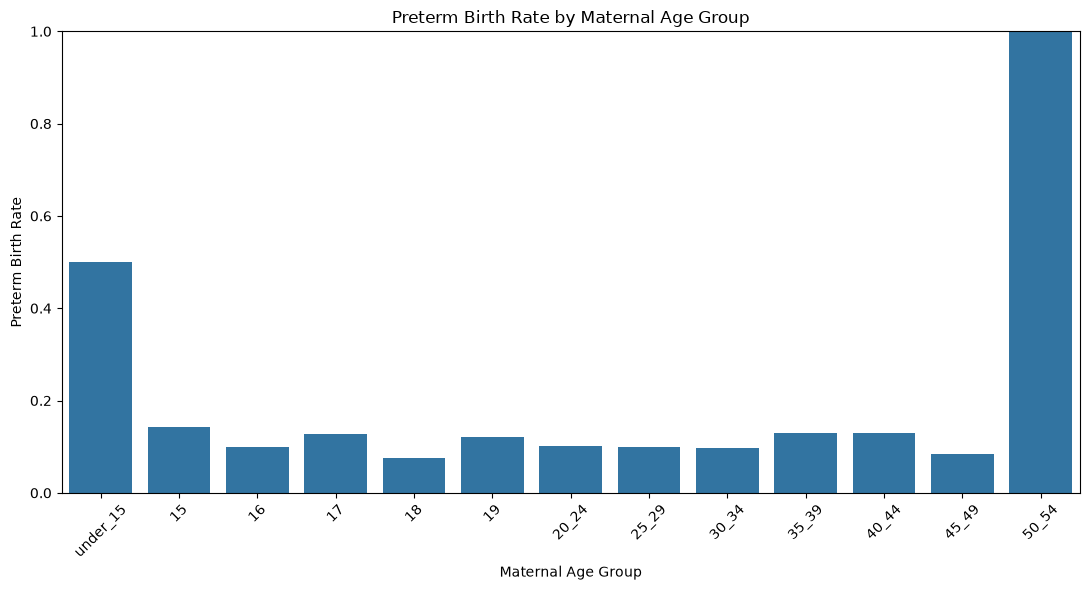

In [67]:
age_order = [
    "under_15", "15", "16", "17", "18", "19",
    "20_24", "25_29", "30_34", "35_39",
    "40_44", "45_49", "50_54"
]

plt.figure(figsize=(11, 6))

sns.barplot(
    data=df,
    x="maternal_age_group",
    y="preterm_birth",
    order=age_order,
    errorbar=None
)

plt.title("Preterm Birth Rate by Maternal Age Group")
plt.xlabel("Maternal Age Group")
plt.ylabel("Preterm Birth Rate")
plt.ylim(0, 1)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("preterm_rate_by_age_group.png", dpi=300, bbox_inches="tight")
plt.show()

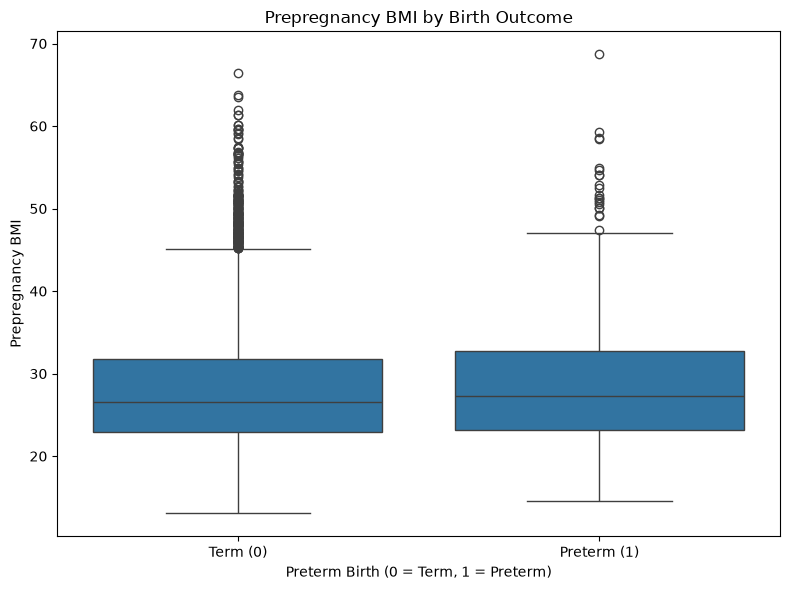

In [68]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="preterm_birth",
    y="prepregnancy_bmi"
)

plt.title("Prepregnancy BMI by Birth Outcome")
plt.xlabel("Preterm Birth (0 = Term, 1 = Preterm)")
plt.ylabel("Prepregnancy BMI")
plt.xticks([0, 1], ["Term (0)", "Preterm (1)"])

plt.tight_layout()
plt.savefig("bmi_by_birth_outcome.png", dpi=300, bbox_inches="tight")
plt.show()

In [69]:
for file in expected_files:
    print(file, "->", os.path.exists(file))

target_distribution.png -> True
preterm_rate_by_education.png -> True
preterm_rate_by_age_group.png -> True
preterm_rate_by_previous_living_children.png -> True
preterm_rate_by_previous_children_deceased.png -> True
bmi_by_birth_outcome.png -> True
preterm_rate_by_diabetes.png -> True
preterm_rate_by_hypertension.png -> True
preterm_rate_by_previous_preterm_birth.png -> True
preterm_rate_by_plurality.png -> True


In [72]:
import reportlab

print("ReportLab version:", reportlab.Version)

ReportLab version: 5.1.0


In [71]:
%pip install reportlab


   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 1.9 MB/s eta 0:00:01
   -------------------- ------------------- 1.0/2.0 MB 2.0 MB/s eta 0:00:01
   ------------------------- -------------- 1.3/2.0 MB 2.0 MB/s eta 0:00:01
   ------------------------------------ --- 1.8/2.0 MB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 2.0 MB/s  0:00:01


In [73]:
import os

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image, PageBreak, KeepTogether
)

# --------------------------------------------------
# 1. DOCUMENT CONFIGURATION
# --------------------------------------------------

pdf_file = "eda_report.pdf"

doc = SimpleDocTemplate(
    pdf_file,
    pagesize=A4,
    rightMargin=1.7 * cm,
    leftMargin=1.7 * cm,
    topMargin=1.7 * cm,
    bottomMargin=1.7 * cm
)

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="CoverTitle",
    parent=styles["Title"],
    fontSize=25,
    leading=32,
    textColor=colors.HexColor("#17365D"),
    alignment=TA_CENTER,
    spaceAfter=20
))

styles.add(ParagraphStyle(
    name="SectionTitle",
    parent=styles["Heading1"],
    fontSize=16,
    leading=21,
    textColor=colors.HexColor("#17365D"),
    spaceBefore=12,
    spaceAfter=10
))

styles.add(ParagraphStyle(
    name="SubTitle",
    parent=styles["Heading2"],
    fontSize=12,
    leading=16,
    textColor=colors.HexColor("#2874A6"),
    spaceBefore=8,
    spaceAfter=6
))

styles.add(ParagraphStyle(
    name="BodyCustom",
    parent=styles["BodyText"],
    fontSize=9.5,
    leading=14,
    alignment=TA_LEFT,
    spaceAfter=8
))

story = []

def add_paragraph(text, style="BodyCustom"):
    story.append(Paragraph(text, styles[style]))

def add_title(text):
    story.append(Paragraph(text, styles["SectionTitle"]))

def add_chart(filename, caption):
    if os.path.exists(filename):
        img = Image(filename)
        img._restrictSize(16 * cm, 8.5 * cm)
        story.append(img)
        story.append(Paragraph(caption, styles["Italic"]))
        story.append(Spacer(1, 10))
    else:
        add_paragraph("Chart unavailable: " + filename)


# --------------------------------------------------
# 2. COVER PAGE
# --------------------------------------------------

story.append(Spacer(1, 3 * cm))

add_paragraph(
    "EXPLORATORY DATA ANALYSIS",
    "CoverTitle"
)

add_paragraph(
    "Preterm Birth Prediction Using Maternal Features",
    "Heading2"
)

story.append(Spacer(1, 1 * cm))

add_paragraph(
    "<b>Dataset:</b> Natality Sample Dataset",
)

add_paragraph(
    "<b>Source:</b> CDC / National Center for Health Statistics "
    "(2025 Natality Public Use File; instructor-provided sample)."
)

add_paragraph(
    "<b>Dataset size:</b> 10,000 observations and 10 columns."
)

add_paragraph(
    "<b>Objective:</b> Explore maternal characteristics, assess "
    "data quality, understand the target distribution, and identify "
    "descriptive associations with preterm birth."
)

story.append(Spacer(1, 2 * cm))

add_paragraph(
    "EDA Project Report",
    "Heading2"
)

story.append(PageBreak())


# --------------------------------------------------
# 3. INTRODUCTION
# --------------------------------------------------

add_title("1. Introduction")

add_paragraph(
    "Preterm birth is defined in this project as a delivery occurring "
    "before 37 completed weeks of gestation. The objective of this "
    "Exploratory Data Analysis (EDA) is to understand the dataset, "
    "evaluate its quality, study the distribution of maternal features, "
    "and explore their relationships with the target variable."
)

add_paragraph(
    "The target variable is <b>preterm_birth</b>, where 0 represents "
    "a term birth and 1 represents a preterm birth. The dataset contains "
    "nine input features and one target variable."
)


# --------------------------------------------------
# 4. DATASET OVERVIEW
# --------------------------------------------------

add_title("2. Dataset Overview")

overview_data = [
    ["Property", "Value"],
    ["Number of observations", "10,000"],
    ["Number of columns", "10"],
    ["Input features", "9"],
    ["Target variable", "preterm_birth"],
    ["Target type", "Binary (0 / 1)"],
    ["Dataset dimensions", "10,000 x 10"]
]

table = Table(overview_data, colWidths=[7 * cm, 8 * cm])

table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7),
    ("VALIGN", (0, 0), (-1, -1), "MIDDLE")
]))

story.append(table)
story.append(Spacer(1, 12))

add_paragraph(
    "The input features include maternal age, education, previous "
    "birth history, prepregnancy BMI, diabetes, hypertension, previous "
    "preterm birth history, and pregnancy plurality."
)


# --------------------------------------------------
# 5. DATA QUALITY
# --------------------------------------------------

add_title("3. Data Quality Assessment")

add_paragraph(
    "The initial inspection identified missing values in six input "
    "features. The target variable contains no missing values."
)

missing_data = [
    ["Feature", "Missing", "Percentage"],
    ["maternal_education", "141", "1.41%"],
    ["prior_live_births_now_living", "77", "0.77%"],
    ["prior_live_births_now_dead", "384", "3.84%"],
    ["prepregnancy_bmi", "340", "3.40%"],
    ["prepregnancy_diabetes", "70", "0.70%"],
    ["prepregnancy_hypertension", "70", "0.70%"],
    ["previous_preterm_birth", "70", "0.70%"]
]

table = Table(missing_data, colWidths=[8 * cm, 3 * cm, 3 * cm])

table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 6),
    ("FONTSIZE", (0, 0), (-1, -1), 8)
]))

story.append(table)

story.append(Spacer(1, 10))

add_paragraph(
    "<b>Total missing cells:</b> 1,152, representing approximately "
    "1.15% of all dataset cells. A total of 846 observations (8.46%) "
    "contain at least one missing value."
)

add_paragraph(
    "<b>Duplicate observations:</b> 2,025 repeated rows were identified "
    "using pandas duplicated(). These are repeated occurrences after "
    "the first appearance. They were not automatically removed because "
    "identical feature values do not necessarily identify the same "
    "individual."
)

add_paragraph(
    "<b>Additional investigation:</b> The value 9 in "
    "prior_live_births_now_dead requires verification using the "
    "original data codebook before assigning it a definitive meaning."
)


# --------------------------------------------------
# 6. TARGET DISTRIBUTION
# --------------------------------------------------

add_title("4. Target Variable Analysis")

add_paragraph(
    "The target variable contains two classes. Term births account "
    "for 8,938 observations (89.38%), while preterm births account "
    "for 1,062 observations (10.62%)."
)

add_paragraph(
    "This distribution indicates a noticeable class imbalance. "
    "Consequently, accuracy alone may not provide a reliable evaluation "
    "of future predictive models. Recall, Precision, F1-score, and "
    "the confusion matrix should also be considered."
)

add_chart(
    "target_distribution.png",
    "Figure 1. Distribution of the target variable."
)


# --------------------------------------------------
# 7. FEATURE-TARGET ANALYSIS
# --------------------------------------------------

add_title("5. Feature–Target Analysis")

add_paragraph(
    "The following analyses compare the observed proportion of preterm "
    "births across categories of the input features. These findings "
    "are descriptive and should not be interpreted as causal effects."
)

# Maternal age
add_paragraph("5.1 Maternal Age Group", "SubTitle")

add_paragraph(
    "The largest age groups are 25–29 and 30–34 years. Among the "
    "larger groups, preterm birth rates are approximately 9.79% "
    "to 9.93% for ages 25–34, compared with approximately 12.92% "
    "to 12.95% for ages 35–44. Very small age categories require "
    "caution when interpreting their percentages."
)

add_chart(
    "preterm_rate_by_age_group.png",
    "Figure 2. Preterm birth rate by maternal age group."
)

# Education
add_paragraph("5.2 Maternal Education", "SubTitle")

add_paragraph(
    "The observed preterm birth rate is highest in the "
    "grade_9_to_12_no_diploma category (16.92%). It is 7.76% "
    "among mothers with a bachelor's degree and 7.28% among those "
    "with a doctorate or professional degree. These differences "
    "are descriptive and may be influenced by other factors."
)

add_chart(
    "preterm_rate_by_education.png",
    "Figure 3. Preterm birth rate by maternal education."
)

# Previous living children
add_paragraph("5.3 Previous Live Births Now Living", "SubTitle")

add_paragraph(
    "The observed preterm birth proportion generally increases "
    "across several categories from zero to seven previous living "
    "children. Categories with very few observations, particularly "
    "eight or more, have unstable percentages."
)

add_chart(
    "preterm_rate_by_previous_living_children.png",
    "Figure 4. Preterm birth rate by previous living children."
)

# Previous deceased children
add_paragraph("5.4 Previous Live Births Now Deceased", "SubTitle")

add_paragraph(
    "Most observations have a value of zero. The remaining categories "
    "contain very few observations, making their preterm birth rates "
    "difficult to interpret reliably. The special value 9 also requires "
    "codebook verification."
)

add_chart(
    "preterm_rate_by_previous_children_deceased.png",
    "Figure 5. Preterm birth rate by previous children now deceased."
)

# BMI
add_paragraph("5.5 Prepregnancy BMI", "SubTitle")

add_paragraph(
    "The mean prepregnancy BMI is approximately 28.00 in the term "
    "group and 28.67 in the preterm group. The corresponding medians "
    "are 26.6 and 27.3. The interquartile range method identified "
    "262 potential high-end outliers (2.71% of non-missing BMI values). "
    "These observations were not automatically removed."
)

add_chart(
    "bmi_by_birth_outcome.png",
    "Figure 6. Prepregnancy BMI distribution by birth outcome."
)

# Diabetes
add_paragraph("5.6 Prepregnancy Diabetes", "SubTitle")

add_paragraph(
    "The preterm birth rate is 10.14% among mothers without "
    "prepregnancy diabetes and 35.03% among mothers with diabetes. "
    "The diabetic group contains 157 observations, so its rate "
    "should be interpreted cautiously."
)

add_chart(
    "preterm_rate_by_diabetes.png",
    "Figure 7. Preterm birth rate by prepregnancy diabetes status."
)

# Hypertension
add_paragraph("5.7 Prepregnancy Hypertension", "SubTitle")

add_paragraph(
    "The preterm birth rate is 9.92% among mothers without "
    "prepregnancy hypertension and 20.98% among mothers with "
    "hypertension. The hypertensive group contains 553 observations."
)

add_chart(
    "preterm_rate_by_hypertension.png",
    "Figure 8. Preterm birth rate by prepregnancy hypertension status."
)

# Previous preterm birth
add_paragraph("5.8 Previous Preterm Birth", "SubTitle")

add_paragraph(
    "The preterm birth rate is 8.89% among mothers without a previous "
    "preterm birth and 34.82% among mothers with such a history. "
    "This feature shows a substantial descriptive difference "
    "between the two groups."
)

add_chart(
    "preterm_rate_by_previous_preterm_birth.png",
    "Figure 9. Preterm birth rate by previous preterm birth history."
)

# Plurality
add_paragraph("5.9 Pregnancy Plurality", "SubTitle")

add_paragraph(
    "The preterm birth rate is 8.88% for singleton pregnancies, "
    "60.62% for twin pregnancies, and 100% for triplet pregnancies. "
    "However, the triplet category contains only six observations, "
    "so its percentage is highly uncertain."
)

add_chart(
    "preterm_rate_by_plurality.png",
    "Figure 10. Preterm birth rate by pregnancy plurality."
)


# --------------------------------------------------
# 8. KEY FINDINGS
# --------------------------------------------------

add_title("6. Key Findings")

findings = [
    "The dataset contains 10,000 observations and nine input features.",
    "The target variable is imbalanced, with 10.62% preterm births.",
    "Missing values affect six input features.",
    "Repeated rows require investigation before deciding whether any should be removed.",
    "Higher observed preterm birth proportions occur in the diabetes, hypertension, previous preterm birth, and twin pregnancy groups.",
    "The triplet category is too small for reliable generalization.",
    "Prepregnancy BMI shows a modest difference between term and preterm groups."
]

for item in findings:
    add_paragraph("• " + item)


# --------------------------------------------------
# 9. PREPROCESSING CONSIDERATIONS
# --------------------------------------------------

add_title("7. Preprocessing Considerations")

add_paragraph(
    "<b>Missing values:</b> Investigate missingness and select suitable "
    "imputation strategies. Missing categorical values must not "
    "automatically be interpreted as No."
)

add_paragraph(
    "<b>Categorical encoding:</b> Use One-Hot Encoding for nominal "
    "features such as diabetes, hypertension, previous preterm birth, "
    "and plurality. Preserve meaningful order when using ordinal "
    "encoding for age and education."
)

add_paragraph(
    "<b>Numerical features:</b> Consider suitable scaling where "
    "required by the selected algorithm. Investigate BMI outliers "
    "and unusual count values rather than removing them automatically."
)

add_paragraph(
    "<b>Data leakage prevention:</b> Split the dataset into training "
    "and test sets before fitting imputers, scalers, or encoders. "
    "Fit preprocessing steps using training data only."
)

add_paragraph(
    "<b>Class imbalance:</b> Consider class-sensitive evaluation "
    "and appropriate strategies for the minority class during "
    "model development."
)


# --------------------------------------------------
# 10. CONCLUSION
# --------------------------------------------------

add_title("8. Conclusion")

add_paragraph(
    "The exploratory analysis provided an overview of the dataset's "
    "structure, quality, target distribution, and feature relationships. "
    "It identified missing values, repeated observations, potential "
    "outliers, and several descriptive associations with preterm birth."
)

add_paragraph(
    "The results provide a foundation for the next stage of the project: "
    "data preprocessing and predictive modeling. All preprocessing "
    "decisions must be validated carefully, and observed associations "
    "should not be interpreted as causal relationships."
)

story.append(Spacer(1, 20))

add_paragraph(
    "<b>End of Exploratory Data Analysis Report</b>",
    "Heading2"
)


# --------------------------------------------------
# 11. BUILD PDF
# --------------------------------------------------

doc.build(story)

print("PDF successfully generated!")
print("File:", os.path.abspath(pdf_file))
print("File exists:", os.path.exists(pdf_file))
print("File size:", round(os.path.getsize(pdf_file) / 1024, 2), "KB")

PDF successfully generated!
File: C:\Users\utilisateur\Desktop\projet_fin_annee\eda_report.pdf
File exists: True
File size: 1155.0 KB


In [75]:
import os

project_files = [
    "eda_analysis.ipynb",
    "feature_dictionary.csv",
    "missing_values_report.csv",
    "target_distribution.png",
    "eda_report.pdf"
]

print("FINAL PROJECT FILES")
print("-" * 45)

for file in project_files:
    exists = os.path.exists(file)
    status = "READY" if exists else "MISSING"
    print(f"{file:<35} {status}")

FINAL PROJECT FILES
---------------------------------------------
eda_analysis.ipynb                  READY
feature_dictionary.csv              READY
missing_values_report.csv           READY
target_distribution.png             READY
eda_report.pdf                      READY
